# In the Quest of Interpreting World Models


## 1.0 Introduction

In this experiment, we will build a key-door grid world where, purely as an artifact of how we generate training data, the background color is perfectly correlated with which quadrant of the grid the agent occupies. For the purposes of this experiment, we will assign the following quadrant colors:

(top-left = red, bottom-right = blue).

This confound is introduced deliberately in the study not as part of the real rules within the environment.

We will train a small autoregressive world model (Tiny Transformer) to predict the next state given the actions prior. Evaluating the model on a held out environment where the color schema is flipped, we will test whether the model's performance collapses.

If the model collapses, we will have verified that the model was relying on color.

We will then mechanistically "open up" the model's hidden activations, train linear probes to show the color shortcut is explicitly encoded, attempt to surgically remove the direction from the activations using TransformerLens hooks and check whether Out-Of-Distribution accuracy can be recovered.


We will compare this patching technique against a training time fix (adversarial penalty that discourages shortcut from forming in the first place) when we grow the small world model.

## 1.1 Setting Up

This notebook auto-detects whether it's running on Google Colab or locally, and installs/selects devices accordingly (see the cell below). Two ways to run it:

**Option A — Google Colab.** Just open this notebook in Colab and run cells top to bottom. If you want GPU acceleration, set Runtime -> Change runtime type -> GPU before running (optional -- the model is tiny enough that CPU works fine too). No manual install needed; the pip-install cell below handles it.

**Option B — Local Mac (Apple Silicon).** Set up an isolated environment from a terminal in this project's folder, *before* opening this notebook:

```bash
python3 -m venv wm-interp
source wm-interp/bin/activate
pip install --upgrade pip
pip install gymnasium minigrid torch transformer_lens sae-lens scikit-learn matplotlib seaborn ipykernel
python -m ipykernel install --user --name wm-interp --display-name "Python (wm-interp)"
```

Then open this notebook and select the **"Python (wm-interp)"** kernel (Kernel -> Change Kernel in Jupyter, or the kernel picker in VS Code).

**On device selection**: this notebook deliberately runs on CPU on Apple Silicon rather than MPS -- TransformerLens warns that PyTorch's MPS backend can silently produce incorrect results on some ops, which would be worse than slow for a project whose conclusions depend on exact activation math (probe directions, orthogonal projections, hook-based ablation). On Colab, CUDA is used automatically when available (no MPS pitfall there), falling back to CPU otherwise. Because CPU and CUDA execution aren't bit-exact even with identical seeds, treat cross-platform comparisons as "consistent within noise," not byte-identical.

In [ ]:
import sys
import os

os.makedirs("artifacts", exist_ok=True)   # figures (plt.savefig) all land here, not repo root

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

RUN_TAG = "colab" if IN_COLAB else "mac"
RANDOM_SEED = 0

print(f"Running in {'Google Colab' if IN_COLAB else 'a local environment'} (RUN_TAG='{RUN_TAG}')")

In [ ]:
!{sys.executable} -m pip install -q gymnasium minigrid torch transformer_lens sae-lens scikit-learn matplotlib seaborn

## 2.1 Building the Confounded Grid World

Here, we will build on MiniGrid's built-in DoorKey environment: the agent must pick up a key, use it to unlock a door, and reach the goal square. MiniGrid follows the standard Gymnasium API (reset(), step(action))

In [2]:
import gymnasium as gym
import minigrid
from minigrid.wrappers import FullyObsWrapper, ImgObsWrapper


env = gym.make("MiniGrid-DoorKey-6x6-v0", render_mode="rgb_array")
env = FullyObsWrapper(env)   # full grid visible (no partial observability) — simplifies this project
obs, info = env.reset(seed=0)
print(obs["image"].shape)   # (H, W, 3) grid of (object, color, state) triples


(6, 6, 3)


Let's try to encode the representation in nummbers!

In [3]:
grid = obs["image"]

print("Object type codes:")
print(grid[:, :, 0])
print()
print("Color codes:")
print(grid[:, :, 1])
print()
print("State codes:")
print(grid[:, :, 2])
print()
print("Agent position (x, y):", env.unwrapped.agent_pos)
print("Agent direction:", env.unwrapped.agent_dir)

Object type codes:
[[ 2  2  2  2  2  2]
 [ 2  1  1 10  1  2]
 [ 2  1  1  5  1  2]
 [ 2  4  2  2  2  2]
 [ 2  1  1  1  8  2]
 [ 2  2  2  2  2  2]]

Color codes:
[[5 5 5 5 5 5]
 [5 0 0 0 0 5]
 [5 0 0 4 0 5]
 [5 4 5 5 5 5]
 [5 0 0 0 1 5]
 [5 5 5 5 5 5]]

State codes:
[[0 0 0 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 0 0]
 [0 2 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]

Agent position (x, y): (np.int64(1), np.int64(3))
Agent direction: 1


But what do they mean in human language? and visually?

In [4]:
from minigrid.core.constants import IDX_TO_OBJECT, IDX_TO_COLOR

for row in grid[:, :, 0]:
    print([IDX_TO_OBJECT[i] for i in row])

['wall', 'wall', 'wall', 'wall', 'wall', 'wall']
['wall', 'empty', 'empty', 'agent', 'empty', 'wall']
['wall', 'empty', 'empty', 'key', 'empty', 'wall']
['wall', 'door', 'wall', 'wall', 'wall', 'wall']
['wall', 'empty', 'empty', 'empty', 'goal', 'wall']
['wall', 'wall', 'wall', 'wall', 'wall', 'wall']


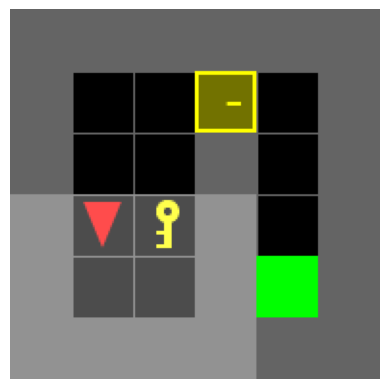

In [5]:
import matplotlib.pyplot as plt

frame = env.render()
plt.imshow(frame)
plt.axis("off")
plt.show()

## 2.2 Injecting the confound: quadrant-correlated background color


Here, we write a Gymnasium ObservationWrapper that, at every step, checks which quadrant the agent occupies and overwrites a dedicated background channel (or a fixed border region of the grid) with a color code that is perfectly determined by the quadrant.

This is our injected confound — it carries zero information the model needs, but it is trivially easy to read off for future verifications.


In [6]:
import numpy as np

class QuadrantColorConfound(gym.ObservationWrapper):
    """
    Paints a border strip of the observation with a color that is a
    deterministic (and, during training, *reversible*) function of the
    agent's quadrant. flip=False reproduces the training scheme;
    flip=True is the OOD test condition.
    """
    def __init__(self, env, flip=False):
        super().__init__(env)
        self.flip = flip

    def observation(self, obs):
        grid = obs["image"].copy()
        H, W, _ = grid.shape
        ax, ay = self.env.unwrapped.agent_pos
        top_left = ax < W // 2 and ay < H // 2
        bottom_right = ax >= W // 2 and ay >= H // 2
        # color codes appended as an extra channel value in the border row
        RED, BLUE, NEUTRAL = 0, 2, 5
        color = NEUTRAL
        if top_left:
            color = BLUE if self.flip else RED
        elif bottom_right:
            color = RED if self.flip else BLUE
        grid[0, :, 1] = color   # overwrite the color channel of row 0 (a MiniGrid convention: axis -1 index 1 is the 'color' field)
        obs["image"] = grid
        return obs

train_env = QuadrantColorConfound(FullyObsWrapper(gym.make("MiniGrid-DoorKey-6x6-v0", render_mode="rgb_array")), flip=False)
ood_env   = QuadrantColorConfound(FullyObsWrapper(gym.make("MiniGrid-DoorKey-6x6-v0", render_mode="rgb_array")), flip=True)


In [7]:
obs_t, _ = train_env.reset(seed=2)
obs_o, _ = ood_env.reset(seed=2)
print("Agent pos:", train_env.unwrapped.agent_pos)
print("train (flip=False) row 0 color:", obs_t["image"][0, :, 1])
print("ood   (flip=True)  row 0 color:", obs_o["image"][0, :, 1])

Agent pos: (np.int64(2), np.int64(2))
train (flip=False) row 0 color: [0 0 0 0 0 0]
ood   (flip=True)  row 0 color: [2 2 2 2 2 2]


## 2.3 Collecting the training dataset

We roll out actions to collect several thousand transitions (s_t, a_t, s_{t+1}) from the confounded environment, saving both position labels and the confounded observation at every step.

**A pure random policy turned out to be too sparse for this task.** DoorKey is a well-known hard-exploration RL benchmark: instrumenting 800 episodes of `env.action_space.sample()` showed the goal reached **0 times**, and the door open for only **~1% of timesteps** -- the environment's two defining mechanics were almost entirely absent from the data. This is a known property of DoorKey under random exploration, not a flaw in the environment itself (see `findings.md` Sec 10 for the full instrumented breakdown).

So instead we mix in a lightweight, hand-rolled **BFS-based scripted policy** (defined below) that plans a route to the key, picks it up, routes to the door, toggles it, then routes to the goal -- mixed stochastically with pure-random episodes, plus injected random noise even within scripted episodes. This keeps the "wide coverage of weird situations" benefit of random exploration (walking into walls, trying the door before it's unlocked, etc.) while making sure door-toggling and goal-completion actually show up often enough to train and evaluate on.

For every timestep, we record:

- `obs` -- the confounded observation before the action is taken
- `action` -- the action taken (scripted or random)
- `next_obs` -- the confounded observation after the action is taken
- `agent_pos` -- the ground-truth (x1, y1) position at `obs`, captured before stepping
- `next_agent_pos` -- the ground-truth (x2, y2) position at `next_obs`, captured after stepping

We save both position labels -- not just one -- because they open possibilities to answer two different probing questions in the future: does the model's hidden state linearly encode where the agent currently is, or where the agent is about to end up? Keeping both lets us run and compare both probes.

In [ ]:
from collections import deque

# --- A lightweight, dependency-free BFS scripted policy -------------------
# Motivation: a pure-random policy almost never executes the precise
# navigate -> pickup -> navigate -> toggle -> navigate sequence DoorKey
# requires (see findings.md Sec 10 -- door open 1.05% of timesteps, goal
# reached 0/800 episodes under random actions). This planner is deliberately
# simple (greedy BFS on the fully-observed grid, no learning) -- it exists
# to densify the training/eval data with the environment's rare-but-defining
# events, not to be a good "agent".
#
# Validated standalone before being written into this notebook: 800
# episodes at SCRIPTED_POLICY_PROB=0.5 raised door-open coverage from 3.6%
# of episodes to 49.0%, and goal-reached from 0.0% to 46.9%; a pure-scripted
# (no noise) sanity run reached 100%/100%/100%, confirming the planner logic
# itself is correct.

SCRIPTED_POLICY_PROB = 0.5   # fraction of episodes that use the scripted planner at all
SCRIPTED_NOISE_PROB = 0.1    # even within a scripted episode, take a random action this often

DIR_VEC = {0: (1, 0), 1: (0, 1), 2: (-1, 0), 3: (0, -1)}   # MiniGrid convention: 0=right,1=down,2=left,3=up


def _dir_to(delta):
    for d, vec in DIR_VEC.items():
        if vec == delta:
            return d
    return None


def _find_all(grid, obj_type):
    """All (x, y) grid coordinates holding an object of the given type."""
    return [(x, y) for x in range(grid.width) for y in range(grid.height)
            if (cell := grid.get(x, y)) is not None and cell.type == obj_type]


def _bfs_path(grid, start, is_passable, target):
    """Shortest 4-connected grid path from start to target, or None if unreachable."""
    if start == target:
        return [start]
    visited = {start}
    parent = {start: None}
    q = deque([start])
    while q:
        cur = q.popleft()
        if cur == target:
            break
        cx, cy = cur
        for dx, dy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nxt = (cx + dx, cy + dy)
            if not (0 <= nxt[0] < grid.width and 0 <= nxt[1] < grid.height) or nxt in visited:
                continue
            if not is_passable(nxt):
                continue
            visited.add(nxt)
            parent[nxt] = cur
            q.append(nxt)
    if target not in visited:
        return None
    path = [target]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    path.reverse()
    return path


def scripted_action(unwrapped_env, phase):
    """One step of a 3-phase (key -> door -> goal) greedy BFS planner.

    Returns (action, next_phase). action is None when the planner has
    nothing useful to propose (target not visible, unreachable, etc.) --
    the caller should fall back to a random action in that case.
    """
    grid = unwrapped_env.grid
    ax, ay = unwrapped_env.agent_pos
    agent_dir = unwrapped_env.agent_dir

    if phase == "key" and unwrapped_env.carrying is not None:
        phase = "door"
    if phase == "door":
        doors = _find_all(grid, "door")
        if doors and grid.get(*doors[0]).is_open:
            phase = "goal"

    if phase == "key":
        targets = _find_all(grid, "key")
        interact_action = 3   # pickup
    elif phase == "door":
        targets = _find_all(grid, "door")
        interact_action = 5   # toggle
    elif phase == "goal":
        targets = _find_all(grid, "goal")
        interact_action = None   # just walk onto it
    else:
        return None, phase

    if not targets:
        return None, phase
    target = targets[0]

    def passable(cell_xy):
        if cell_xy == (ax, ay):
            return True
        cell = grid.get(*cell_xy)
        if cell is None:
            return True
        if cell_xy == target and interact_action is not None:
            return False   # can't walk onto the key/door cell itself -- must stand adjacent
        return cell.can_overlap()

    if interact_action is None:
        bfs_target_candidates = [target]
    else:
        tx, ty = target
        bfs_target_candidates = []
        for dx, dy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            cx, cy = tx + dx, ty + dy
            if 0 <= cx < grid.width and 0 <= cy < grid.height:
                c = grid.get(cx, cy)
                if c is None or c.can_overlap():
                    bfs_target_candidates.append((cx, cy))
        if not bfs_target_candidates:
            return None, phase

    best_path = None
    for cand in bfs_target_candidates:
        p = _bfs_path(grid, (ax, ay), passable, cand)
        if p is not None and (best_path is None or len(p) < len(best_path)):
            best_path = p
    if best_path is None:
        return None, phase

    if len(best_path) == 1:
        if interact_action is None:
            return None, phase   # already standing on the goal cell
        fx, fy = target
        desired_dir = _dir_to((fx - ax, fy - ay))
        if desired_dir is None:
            return None, phase
        if agent_dir == desired_dir:
            return interact_action, phase
        diff = (desired_dir - agent_dir) % 4
        return (0 if diff == 3 else 1), phase   # 0=turn left, 1=turn right (shorter turn)

    nxt = best_path[1]
    desired_dir = _dir_to((nxt[0] - ax, nxt[1] - ay))
    if agent_dir == desired_dir:
        return 2, phase   # forward
    diff = (desired_dir - agent_dir) % 4
    return (0 if diff == 3 else 1), phase


def choose_action(env, rng, use_scripted, phase):
    """Wraps scripted_action with the noise-injection and random fallback
    used by both data collection and eval -- written once, reused everywhere."""
    if use_scripted and rng.random() > SCRIPTED_NOISE_PROB:
        action, phase = scripted_action(env.unwrapped, phase)
        if action is not None:
            return action, phase
    return int(rng.integers(env.action_space.n)), phase

In [ ]:
def collect_trajectories(env, n_episodes=500, max_steps=50, seed0=0):
    data = []
    for ep in range(n_episodes):
        obs, info = env.reset(seed=seed0 + ep)
        rng = np.random.default_rng(seed0 + ep)   # decoupled from gym's own RNG, for reproducibility
        use_scripted = rng.random() < SCRIPTED_POLICY_PROB
        phase = "key"
        for t in range(max_steps):
            pos_before = env.unwrapped.agent_pos
            action, phase = choose_action(env, rng, use_scripted, phase)
            next_obs, reward, terminated, truncated, info = env.step(action)
            pos_after = env.unwrapped.agent_pos
            data.append({
                "obs": obs["image"] if isinstance(obs, dict) else obs,
                "action": action,
                "next_obs": next_obs["image"] if isinstance(next_obs, dict) else next_obs,
                "agent_pos": pos_before,       # matches obs
                "next_agent_pos": pos_after,   # matches next_obs
            })
            obs = next_obs
            if terminated or truncated:
                break
    return data

In [ ]:
def _event_coverage(policy_scripted_prob, n_episodes=200, seed0=90_000):
    """Quick, cheap replay of the same instrumentation used to diagnose the
    exploration bottleneck (findings.md Sec 10) -- confirms in-notebook that
    the scripted-policy mix actually fixes it, not just in a side script."""
    key_c, door_c, goal_c = 0, 0, 0
    for ep in range(n_episodes):
        obs, info = train_env.reset(seed=seed0 + ep)
        rng = np.random.default_rng(seed0 + ep)
        use_scripted = rng.random() < policy_scripted_prob
        phase = "key"
        unwrapped = train_env.unwrapped
        key_seen = door_seen = goal_seen = False
        for t in range(50):
            action, phase = choose_action(train_env, rng, use_scripted, phase)
            obs, reward, terminated, truncated, info = train_env.step(action)
            if unwrapped.carrying is not None:
                key_seen = True
            doors = _find_all(unwrapped.grid, "door")
            if doors and unwrapped.grid.get(*doors[0]).is_open:
                door_seen = True
            if terminated and reward > 0:
                goal_seen = True
            if terminated or truncated:
                break
        key_c += int(key_seen); door_c += int(door_seen); goal_c += int(goal_seen)
    return {
        "key_pickup_rate": key_c / n_episodes,
        "door_open_rate": door_c / n_episodes,
        "goal_reach_rate": goal_c / n_episodes,
    }


policy_coverage_check = {
    "pure_random": _event_coverage(0.0),
    "mixed_policy": _event_coverage(SCRIPTED_POLICY_PROB),
}
for label, stats in policy_coverage_check.items():
    print(f"{label:15s}  key={stats['key_pickup_rate']:.1%}  door={stats['door_open_rate']:.1%}  goal={stats['goal_reach_rate']:.1%}")

In [9]:
train_data = collect_trajectories(train_env, n_episodes=800)

## 3.1 Training the World Model

We will train a small autoregressive Transformer that takes a short history of (state, action) tokens and predicts the next state. Because TransformerLens is built to wrap architectures defined by a HookedTransformerConfig, the cleanest path is to build our model directly through TransformerLens rather than writing a raw nn.Module and converting it later.

Thanks to all the builders before me who made inheritance of complex code easy and simple.

In [10]:
N_OBJECTS = 11       # len(IDX_TO_OBJECT)
N_COLOR_SLOTS = 6    # 6 if using Option 2 (real colors), 7 if using Option 1 (synthetic 6/BLUE)
N_STATES = 3         # 0=open/unused, 1=closed, 2=locked -- max observed state value + 1
N_ACTIONS = 7         # env.action_space.n

In [11]:
def cell_to_token(obj, color, state):
    """Flatten one (object, color, state) triple into a single integer token."""
    return (obj * N_COLOR_SLOTS * N_STATES) + (color * N_STATES) + state

CELL_VOCAB_SIZE = N_OBJECTS * N_COLOR_SLOTS * N_STATES
ACTION_TOKEN_OFFSET = CELL_VOCAB_SIZE   # actions start right after all possible cell tokens
VOCAB_SIZE = CELL_VOCAB_SIZE + N_ACTIONS

def action_to_token(action):
    return ACTION_TOKEN_OFFSET + action

In [12]:
from minigrid.core.constants import IDX_TO_OBJECT, IDX_TO_COLOR
assert N_OBJECTS == len(IDX_TO_OBJECT)
assert N_COLOR_SLOTS >= len(IDX_TO_COLOR)  # >= not == , since Option 1 needs a slot beyond len(IDX_TO_COLOR)
print("VOCAB_SIZE:", VOCAB_SIZE)

VOCAB_SIZE: 205


In [ ]:
from transformer_lens import HookedTransformer, HookedTransformerConfig
import torch

cfg = HookedTransformerConfig(
    n_layers=2,
    d_model=128,
    n_ctx=48,          # length of (state, action) history the model conditions on
    d_head=32,
    n_heads=4,
    d_mlp=512,
    d_vocab=VOCAB_SIZE,   # size of your discretized state+action token vocabulary
    act_fn="gelu",
    normalization_type="LN",
    # MPS deliberately skipped: TransformerLens warns that PyTorch's MPS
    # backend can silently produce incorrect results on some ops. For a
    # project whose conclusions hinge on exact activation math (probe
    # directions, orthogonal projections, hook-based ablation), a silent
    # numerical error is worse than no acceleration at all. The model is
    # tiny enough that CPU is still fast. This also does the right thing on
    # Colab: prefers CUDA when available (no MPS pitfall there either),
    # falls back to CPU otherwise.
    device="cuda" if torch.cuda.is_available() else "cpu",
)
torch.manual_seed(RANDOM_SEED)
model = HookedTransformer(cfg)

In [ ]:
print("Environment:", RUN_TAG, "| Device:", cfg.device)

## Tokenizing the grid world

Transformers operate on discrete tokens, so we need a small tokenization scheme before training. We flatten each grid cell's `(object, color, state)` triple into a single integer via `cell_to_token`, then represent one timestep as `[cell_0, cell_1, ..., cell_35, action]` — the 36 flattened grid cells followed by the action taken from that state. With an 11-object x 6-color x 3-state cell vocabulary plus 7 action tokens, the whole vocabulary is a few hundred tokens, which keeps training fast even on a laptop.

## Training Loop

The model is trained to predict the next grid state from `(current grid, action)`. One subtlety matters here: `HookedTransformer` is causal, so a token at sequence position *i* only ever attends to positions ≤ *i*. Our input sequence is `[cell_0, ..., cell_35, action]`, which means positions 0 through 35 never see the action — only the final position (the action token) has attended to the whole grid *and* the action. So next-state prediction has to be read off that last position, not off the model's own per-position unembedding logits. `next_state_head` (defined above) is a small linear layer on top of that last-position residual stream that predicts all 36 next-cell tokens at once, and it's trained jointly with the transformer below.

In [15]:
import torch

def flatten_grid_to_tokens(grid):
    """(H, W, 3) grid -> flat list of cell tokens, one per cell."""
    H, W, _ = grid.shape
    tokens = []
    for y in range(H):
        for x in range(W):
            obj, color, state = grid[y, x]
            tokens.append(cell_to_token(int(obj), int(color), int(state)))
    return tokens

def build_token_dataset(data):
    input_seqs = []
    target_seqs = []
    for transition in data:
        obs_tokens = flatten_grid_to_tokens(transition["obs"])
        act_token = action_to_token(transition["action"])
        next_obs_tokens = flatten_grid_to_tokens(transition["next_obs"])

        # input: all cells of the current grid + the action taken
        input_ids = obs_tokens + [act_token]
        # target: only the next grid's cells. These are predicted from the
        # LAST position's hidden state (see predict_next_grid_logits below),
        # since that is the only position in a causal model that has seen
        # both the full grid AND the action.
        target_ids = next_obs_tokens

        input_seqs.append(input_ids)
        target_seqs.append(target_ids)

    input_ids = torch.tensor(input_seqs, dtype=torch.long)
    target_ids = torch.tensor(target_seqs, dtype=torch.long)
    return TensorDataset(input_ids, target_ids)

In [16]:
import torch.nn as nn

GRID_CELLS = 36  # 6x6 grid, flattened (matches MiniGrid-DoorKey-6x6-v0)
LAST_LAYER_RESID = f"blocks.{cfg.n_layers - 1}.hook_resid_post"

# The transformer is causal: position i only attends to positions <= i.
# The input sequence is [cell_0, ..., cell_35, action], so positions 0..35
# never see the action and structurally cannot predict the post-action
# grid -- the only position with full context (all 36 cells AND the
# action) is the last one. So next-state prediction has to be read off
# THAT position, via a dedicated head, rather than off `model`'s own
# per-position unembed logits (which is what the buggy version of this
# notebook did, via `logits[0, :36]`).
next_state_head = nn.Linear(cfg.d_model, GRID_CELLS * CELL_VOCAB_SIZE).to(cfg.device)

def predict_next_grid_logits(model, head, input_ids):
    """input_ids: (batch, 37) -> logits: (batch, GRID_CELLS, CELL_VOCAB_SIZE)"""
    _, cache = model.run_with_cache(input_ids, names_filter=LAST_LAYER_RESID)
    h_last = cache[LAST_LAYER_RESID][:, -1, :]   # (batch, d_model) -- action-informed
    return head(h_last).view(-1, GRID_CELLS, CELL_VOCAB_SIZE)

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

train_ds = build_token_dataset(train_data)
loader = DataLoader(train_ds, batch_size=64, shuffle=True)
opt = torch.optim.AdamW(list(model.parameters()) + list(next_state_head.parameters()), lr=3e-4)

N_EPOCHS = 100
for epoch in range(N_EPOCHS):
    total_loss = 0.0
    for input_ids, target_ids in loader:
        input_ids, target_ids = input_ids.to(cfg.device), target_ids.to(cfg.device)
        pred_logits = predict_next_grid_logits(model, next_state_head, input_ids)  # (batch, GRID_CELLS, CELL_VOCAB_SIZE)
        loss = torch.nn.functional.cross_entropy(
            pred_logits.reshape(-1, CELL_VOCAB_SIZE), target_ids.reshape(-1)
        )
        opt.zero_grad(); loss.backward(); opt.step()
        total_loss += loss.item()
    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(f"epoch {epoch}: loss {total_loss / len(loader):.4f}")

### The OOD Test — Generalization Collapse

Now we roll the trained model out autoregressively on the flipped-color environment (`ood_env`) and compare its next-state prediction accuracy against its accuracy on a held-out in-distribution (non-flipped) test set.

A commonly-seen pattern here is high in-distribution accuracy alongside a sharp drop in OOD accuracy — but on its own that drop is only suggestive, not proof, that the model relied on color. A drop is also consistent with other explanations (e.g. the model being poorly trained, or the OOD shift breaking something unrelated to color). Parts 3 and 4 below exist to rule out those alternative explanations and establish (or rule out) the color shortcut as the specific cause.

In [18]:
def init_history(obs):
    return obs["image"] if isinstance(obs, dict) else obs

def model_predict_next(model, head, history, action):
    input_tokens = flatten_grid_to_tokens(history) + [action_to_token(action)]
    input_ids = torch.tensor([input_tokens], dtype=torch.long, device=cfg.device)
    with torch.no_grad():
        pred_logits = predict_next_grid_logits(model, head, input_ids)   # (1, GRID_CELLS, CELL_VOCAB_SIZE)
    pred_tokens = pred_logits[0].argmax(dim=-1).cpu().numpy()
    return pred_tokens

def true_next_tokens(next_obs):
    next_grid = next_obs["image"] if isinstance(next_obs, dict) else next_obs
    return np.array(flatten_grid_to_tokens(next_grid))

def update_history(history, action, next_obs):
    return next_obs["image"] if isinstance(next_obs, dict) else next_obs

In [ ]:
def evaluate_rollout_accuracy_dual(model, head, env, n_episodes=500):
    exact_correct, exact_total = 0, 0
    cell_correct, cell_total = 0, 0

    for ep in range(n_episodes):
        obs, info = env.reset(seed=10_000 + ep)
        rng = np.random.default_rng(10_000 + ep)   # seeded per-episode: reproducible, and identical
        use_scripted = rng.random() < SCRIPTED_POLICY_PROB   # across baseline/ablated/regularized model calls
        phase = "key"
        history = init_history(obs)
        for t in range(30):
            action, phase = choose_action(env, rng, use_scripted, phase)
            pred_tokens = model_predict_next(model, head, history, action)
            next_obs, reward, terminated, truncated, info = env.step(action)
            true_tokens = true_next_tokens(next_obs)

            exact_correct += int(np.array_equal(pred_tokens, true_tokens))
            exact_total += 1

            cell_correct += int((pred_tokens == true_tokens).sum())
            cell_total += len(true_tokens)

            history = update_history(history, action, next_obs)
            if terminated or truncated:
                break

    return {
        "exact_match_acc": exact_correct / exact_total,
        "per_cell_acc": cell_correct / cell_total,
    }

in_dist = evaluate_rollout_accuracy_dual(model, next_state_head, train_env)
ood     = evaluate_rollout_accuracy_dual(model, next_state_head, ood_env)

print("In-distribution:")
print(f"  exact-match accuracy: {in_dist['exact_match_acc']:.3f}")
print(f"  per-cell accuracy:    {in_dist['per_cell_acc']:.3f}")
print()
print("OOD (flipped color):")
print(f"  exact-match accuracy: {ood['exact_match_acc']:.3f}")
print(f"  per-cell accuracy:    {ood['per_cell_acc']:.3f}")
print()
print(f"Exact-match gap:  {in_dist['exact_match_acc'] - ood['exact_match_acc']:.3f}")
print(f"Per-cell gap:     {in_dist['per_cell_acc'] - ood['per_cell_acc']:.3f}")

## Part 3 — Diagnosing the Latent Representation (Probing)

Before intervening on the model, we first need correlational evidence that the color confound is explicitly represented somewhere in the model's hidden activations. We do this with **linear probes**: simple classifiers (logistic regression / ridge regression) trained to predict a target quantity from a frozen hidden activation.

We collect a fresh batch of trajectories (`eval_data`) and cache the residual stream after each transformer block with `model.run_with_cache`, reading off the activation at the final sequence position (`[:, -1, :]`) — the same action-informed position `next_state_head` predicts from. Two probes are then trained on top of that activation:
- **Probe A** — can we linearly decode the agent's true `(x, y)` position? (evidence of real dynamics tracking)
- **Probe B** — can we linearly decode the background color / quadrant? (evidence of the shortcut)

In [20]:
eval_data = collect_trajectories(train_env, n_episodes=200, seed0=50_000)

def build_input_tokens(data):
    seqs = [flatten_grid_to_tokens(t["obs"]) + [action_to_token(t["action"])] for t in data]
    return torch.tensor(seqs, dtype=torch.long)

xy_positions = np.array([t["agent_pos"] for t in eval_data])   # (n_examples, 2)

def quadrant_label(pos, W=6, H=6):
    x, y = pos
    if x < W // 2 and y < H // 2:
        return 0   # top_left
    elif x >= W // 2 and y >= H // 2:
        return 1   # bottom_right
    else:
        return 2   # neutral / dead zone

color_labels = np.array([quadrant_label(p) for p in xy_positions])

In [21]:
tokens = build_input_tokens(eval_data)   # (n_examples, seq_len)
with torch.no_grad():
    _, cache = model.run_with_cache(
        tokens,
        names_filter=lambda name: "resid_post" in name,   # only cache the residual stream after each block
    )

# Residual stream activation after layer L, at the final sequence position:
L = 0
h = cache["resid_post", L][:, -1, :]   # shape: (n_examples, d_model)

In [22]:
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score

h_np = h.detach().cpu().numpy()

# Probe A: true dynamics -- can we linearly decode (x, y) position?
X_train, X_test, y_train, y_test = train_test_split(h_np, xy_positions, test_size=0.2, random_state=0)
probe_A = Ridge().fit(X_train, y_train)
print("Probe A (true (x,y) position) R^2:", r2_score(y_test, probe_A.predict(X_test)))

# Probe B: spurious shortcut -- can we linearly decode background color / quadrant?
X_train, X_test, c_train, c_test = train_test_split(h_np, color_labels, test_size=0.2, random_state=0)
probe_B = LogisticRegression(max_iter=1000).fit(X_train, c_train)
print("Probe B (background color) accuracy:", accuracy_score(c_test, probe_B.predict(X_test)))


Probe A (true (x,y) position) R^2: 0.7633041143417358
Probe B (background color) accuracy: 1.0


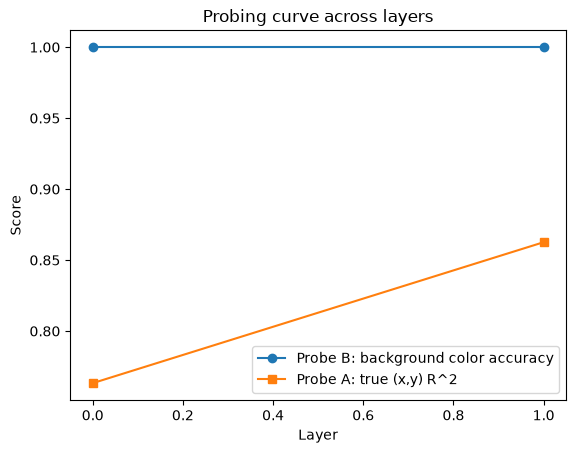

Strongest color-probe layer: L=0 (acc=1.0000)


In [23]:
import matplotlib.pyplot as plt

layers = list(range(cfg.n_layers))
acc_color, r2_xy, probes_B = [], [], []
for Li in layers:
    h_L = cache["resid_post", Li][:, -1, :].detach().cpu().numpy()

    Xtr, Xte, ytr, yte = train_test_split(h_L, xy_positions, test_size=0.2, random_state=0)
    r2_xy.append(r2_score(yte, Ridge().fit(Xtr, ytr).predict(Xte)))

    Xtr, Xte, ctr, cte = train_test_split(h_L, color_labels, test_size=0.2, random_state=0)
    probe_Li = LogisticRegression(max_iter=1000).fit(Xtr, ctr)
    acc_color.append(accuracy_score(cte, probe_Li.predict(Xte)))
    probes_B.append(probe_Li)

plt.plot(layers, acc_color, marker="o", label="Probe B: background color accuracy")
plt.plot(layers, r2_xy, marker="s", label="Probe A: true (x,y) R^2")
plt.xlabel("Layer"); plt.ylabel("Score"); plt.legend(); plt.title("Probing curve across layers")
plt.savefig("artifacts/probing_curve.png", dpi=150)
plt.show()

# Lock in the layer where the color probe is strongest: this is the layer
# we ablate in Part 4, so `probe_B` (and the direction derived from it)
# must come from THIS layer -- not whatever `L` last happened to equal
# after this loop, which is what the notebook relied on before this fix
# (an accident of loop state, not an actual "strongest layer" selection).
L = int(np.argmax(acc_color))
probe_B = probes_B[L]
print(f"Strongest color-probe layer: L={L} (acc={acc_color[L]:.4f})")
for Li in layers:
    if Li != L:
        print(f"(non-selected) Layer {Li}: Probe B acc={acc_color[Li]:.4f}, Probe A R^2={r2_xy[Li]:.4f}")

### Visualizing the shortcut: attention patterns and a PCA projection

Two more visual, complementary tools before moving to causal intervention. Attention patterns show *where in the input* the model looks when computing its prediction -- if it's reading the color confound, we'd expect real attention weight on the row-0 border cells (positions 0-5 in the flattened sequence, where the color channel is overwritten) at the layer where Probe B is strongest. A PCA projection of the same layer's residual stream gives a direct visual read of "color separates cleanly," independent of any probe's classification accuracy number.

In [ ]:
with torch.no_grad():
    _, attn_cache = model.run_with_cache(tokens, names_filter=lambda name: "hook_pattern" in name)

pattern_L = attn_cache["pattern", L]   # (n_examples, n_heads, query_pos, key_pos)
avg_pattern_from_last = pattern_L[:, :, -1, :].mean(dim=0).detach().cpu().numpy()   # (n_heads, key_pos), averaged over examples

fig, axes = plt.subplots(1, cfg.n_heads, figsize=(4 * cfg.n_heads, 3.5))
for head in range(cfg.n_heads):
    ax = axes[head]
    weights = avg_pattern_from_last[head]        # (37,) -- attention from the action token to each input position
    grid_weights = weights[:36].reshape(6, 6)     # cell positions, in row-major grid order (row 0 = y=0, the color row)
    im = ax.imshow(grid_weights, cmap="viridis")
    ax.set_title(f"Layer {L}, Head {head}\n(avg attn from action token)")
    ax.set_xticks([]); ax.set_yticks([])
    ax.add_patch(plt.Rectangle((-0.5, -0.5), 6, 1, fill=False, edgecolor="red", linewidth=2))
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle(f"Attention from the action-informed position to each grid cell (layer {L})\nRed box = row 0, where the color confound lives")
plt.tight_layout()
plt.savefig("artifacts/attention_patterns.png", dpi=150)
plt.show()

row0_weight = avg_pattern_from_last[:, :6].sum(axis=1)     # total attention mass on the color row, per head
rest_weight = avg_pattern_from_last[:, 6:36].sum(axis=1)   # total attention mass on the other 30 cells, per head
for head in range(cfg.n_heads):
    print(f"Head {head}: attention on color row = {row0_weight[head]:.4f}, on rest of grid (30 cells) = {rest_weight[head]:.4f}")

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
h_L_for_pca = cache["resid_post", L][:, -1, :].detach().cpu().numpy()   # same layer/position as the probes above
h_2d = pca.fit_transform(h_L_for_pca)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sc0 = axes[0].scatter(h_2d[:, 0], h_2d[:, 1], c=color_labels, cmap="coolwarm", s=12, alpha=0.7)
axes[0].set_title(f"PCA of layer-{L} residual stream, colored by color/quadrant label")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc0, ax=axes[0], label="color_labels (0=top-left, 1=bottom-right, 2=neutral)")

pos_x = xy_positions[:, 0]
sc1 = axes[1].scatter(h_2d[:, 0], h_2d[:, 1], c=pos_x, cmap="viridis", s=12, alpha=0.7)
axes[1].set_title("Same projection, colored by true agent x-position")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.colorbar(sc1, ax=axes[1], label="agent x position")

plt.tight_layout()
plt.savefig("artifacts/pca_residual_stream.png", dpi=150)
plt.show()

print(f"PCA explained variance ratio (PC1, PC2): {pca.explained_variance_ratio_}")

### Expected diagnosis, and a necessary caution about probing

A well-known pattern in this kind of experiment is for the color probe (Probe B) to reach near-100% accuracy from very early layers — the confound is cheap to represent, so a model that's found it tends to represent it early and strongly. Probe A (true position) may also decode reasonably well; a strong, cleanly-decodable color signal existing *alongside* position doesn't necessarily mean the model relies on it.

**This matters**: a high probe accuracy only shows that color information is linearly *recoverable* from the hidden state — it does **not** by itself prove the model *uses* that information to make its predictions. Probes can succeed on information a model computes but never causally acts on (see *"Revisiting the Othello World Model Hypothesis,"* arXiv:2503.04421, for a detailed treatment of this exact pitfall). This is exactly why Part 4 requires a causal intervention, not just a probe, before we can claim the shortcut is found and fixed.

In [24]:
import numpy as np

w = probe_B.coef_[0]                       # logistic regression weight vector, shape (d_model,)
color_direction = w / np.linalg.norm(w)    # unit vector
color_direction_t = torch.tensor(color_direction, dtype=torch.float32, device=cfg.device)


In [25]:
ood_data = collect_trajectories(ood_env, n_episodes=200, seed0=60_000)
ood_tokens = build_input_tokens(ood_data).to(cfg.device)

## Part 4 — Causal Intervention (Activation Patching)

This is the mechanistic core of the project. We use the direction discovered by Probe B as a hypothesis about which direction in activation space encodes "background color," surgically remove that direction from the residual stream mid-forward-pass with a TransformerLens hook, and test whether doing so causally restores OOD generalization. If it does, we've moved from correlational evidence (the probe) to causal evidence (the intervention).

For a linear probe (logistic regression), the learned weight vector `probe_B.coef_[0]` is itself a direction in activation space that's discriminative for the target label — normalized, it becomes our ablation direction (`color_direction`, defined above).

**Why an orthogonal projection instead of zeroing a neuron?** The probe direction is a linear combination of many neurons, not a single neuron — individual neurons are rarely cleanly monosemantic in a small, non-regularized model. Projecting out the probe direction (subtracting its component from the activation) removes exactly the information the probe reads, without needing to identify a single interpretable neuron. This is the standard "directional ablation" pattern used throughout the activation-patching literature (see Heimersheim, *"How to Use and Interpret Activation Patching,"* arXiv:2404.15255, for a survey of intervention variants).

In [26]:
def ablate_color_direction_hook(resid, hook):
    # resid: (batch, seq, d_model) -- the residual stream at this hook point
    proj = (resid @ color_direction_t).unsqueeze(-1) * color_direction_t
    return resid - proj   # orthogonal projection: removes the color component, leaves the rest untouched

HOOK_NAME = f"blocks.{L}.hook_resid_post"   # L = the layer where Probe B was strongest

with torch.no_grad():
    logits_patched = model.run_with_hooks(
        ood_tokens,
        fwd_hooks=[(HOOK_NAME, ablate_color_direction_hook)],
    )


In [27]:
def run_in_batches(model, tokens, fwd_hooks=None, batch_size=64):
    outputs = []
    with torch.no_grad():
        for i in range(0, tokens.shape[0], batch_size):
            batch = tokens[i:i+batch_size]
            if fwd_hooks:
                out = model.run_with_hooks(batch, fwd_hooks=fwd_hooks)
            else:
                out = model(batch)
            outputs.append(out.cpu())
    return torch.cat(outputs, dim=0)

logits_patched = run_in_batches(model, ood_tokens, fwd_hooks=[(HOOK_NAME, ablate_color_direction_hook)])

In [ ]:
def evaluate_rollout_accuracy_with_hook(model, head, env, hook_name, hook_fn, n_episodes=500):
    exact_correct, exact_total = 0, 0
    cell_correct, cell_total = 0, 0

    captured = {}
    def capture_last_resid(resid, hook):
        captured["h"] = resid[:, -1, :]
        return resid

    # Two hooks: one ablates at `hook_name`, one just records the (possibly
    # already-ablated) final-layer residual so we can feed it to `head`. If
    # hook_name == LAST_LAYER_RESID they fire at the same point, in the
    # order given below, so the capture correctly sees the post-ablation
    # value.
    hooks = [(hook_name, hook_fn), (LAST_LAYER_RESID, capture_last_resid)]

    for ep in range(n_episodes):
        obs, info = env.reset(seed=10_000 + ep)
        rng = np.random.default_rng(10_000 + ep)   # same seeding convention as evaluate_rollout_accuracy_dual
        use_scripted = rng.random() < SCRIPTED_POLICY_PROB   # -> identical action trajectories across models/hooks
        phase = "key"
        history = init_history(obs)
        for t in range(30):
            action, phase = choose_action(env, rng, use_scripted, phase)

            input_tokens = flatten_grid_to_tokens(history) + [action_to_token(action)]
            input_ids = torch.tensor([input_tokens], dtype=torch.long, device=cfg.device)
            with torch.no_grad():
                model.run_with_hooks(input_ids, fwd_hooks=hooks)
                pred_logits = head(captured["h"]).view(1, GRID_CELLS, CELL_VOCAB_SIZE)
            pred_tokens = pred_logits[0].argmax(dim=-1).cpu().numpy()

            next_obs, reward, terminated, truncated, info = env.step(action)
            true_tokens = true_next_tokens(next_obs)

            exact_correct += int(np.array_equal(pred_tokens, true_tokens))
            exact_total += 1
            cell_correct += int((pred_tokens == true_tokens).sum())
            cell_total += len(true_tokens)

            history = update_history(history, action, next_obs)
            if terminated or truncated:
                break

    return {
        "exact_match_acc": exact_correct / exact_total,
        "per_cell_acc": cell_correct / cell_total,
    }

In [29]:
ood_acc_baseline = evaluate_rollout_accuracy_dual(model, next_state_head, ood_env)
ood_acc_patched  = evaluate_rollout_accuracy_with_hook(model, next_state_head, ood_env, hook_name=HOOK_NAME, hook_fn=ablate_color_direction_hook)
in_dist_acc_patched = evaluate_rollout_accuracy_with_hook(model, next_state_head, train_env, hook_name=HOOK_NAME, hook_fn=ablate_color_direction_hook)

print(f"OOD exact-match, unpatched: {ood_acc_baseline['exact_match_acc']:.3f}")
print(f"OOD exact-match, ablated:   {ood_acc_patched['exact_match_acc']:.3f}")
print(f"In-dist exact-match, ablated (control): {in_dist_acc_patched['exact_match_acc']:.3f}")

OOD exact-match, unpatched: 0.018
OOD exact-match, ablated:   0.009
In-dist exact-match, ablated (control): 0.007


### What counts as a successful result (and what doesn't)

A meaningful **positive** result: OOD accuracy recovers substantially toward in-distribution levels after ablation, *and* in-distribution accuracy on the un-flipped environment isn't badly damaged by the same ablation (the control run above). A meaningful **negative** result — ablation does *not* recover OOD accuracy — is equally publishable and equally valuable: it would mean the shortcut is represented elsewhere, distributed non-linearly, or that something other than color is driving the OOD behavior. Don't force a positive result; report what actually happens, and reason about why. If you want a stronger diagnostic before concluding either way, check whether Probe B's accuracy actually drops toward chance on the post-ablation activations (the final cell in this notebook does exactly that) — a probe that still succeeds after ablation despite unchanged OOD accuracy is itself informative.

### Extension: How many directions does the shortcut span?

Ablating a single direction left Probe B at 100% and didn't recover OOD accuracy -- but that doesn't mean the shortcut is causally irrelevant; it may mean color is encoded redundantly across more than one direction at this layer. Here we ablate directions **iteratively**: at each round, fit a fresh probe on the (already partially-ablated) activations, ablate its direction too, and check whether Probe B accuracy eventually collapses toward chance as we remove more directions -- and whether OOD/in-distribution rollout accuracy tracks that collapse.

**Control**: removing *any* k directions from a small residual stream might degrade behavior on its own, regardless of whether those directions encode color. To tell the two apart, we run a second loop in parallel that ablates k *random* unit directions instead of the probe-derived ones, using the exact same evaluation. If probe-derived ablation collapses accuracy no worse than random ablation does, the result doesn't support "this direction was doing real work" -- it would just mean the model is fragile to any comparable perturbation.

In [ ]:
def make_multi_direction_hook(directions):
    """Generalizes ablate_color_direction_hook to project out several unit
    directions at once. An empty list is a no-op (identity) hook."""
    def ablation_hook(resid, hook):
        out = resid
        for d in directions:
            proj = (out @ d).unsqueeze(-1) * d
            out = out - proj
        return out
    return ablation_hook


def run_with_ablation_and_capture(model, tokens, hook_name, hook_fn):
    """Runs the model with `hook_fn` attached at `hook_name` and returns the
    post-hook final-position residual stream (used to re-probe for the next
    round of ablation)."""
    captured = {}
    def combined_hook(resid, hook):
        out = hook_fn(resid, hook)
        captured["h"] = out[:, -1, :].detach()
        return out
    with torch.no_grad():
        model.run_with_hooks(tokens, fwd_hooks=[(hook_name, combined_hook)])
    return captured["h"].cpu().numpy()


def random_unit_direction(d_model, rng):
    """A random direction in activation space, normalized like a probe
    direction -- the control condition for the ablation loop below."""
    v = rng.normal(size=d_model)
    return v / np.linalg.norm(v)

In [ ]:
K_MAX = 5
N_MULTI_EVAL_EPISODES = 200  # cheaper than the main 500-episode eval, since this multiplies by (K_MAX+1) rounds x 2 envs x 2 conditions (greedy + random control)

random_rng = np.random.default_rng(RANDOM_SEED + 999)   # separate stream, dedicated to the control condition


def run_ablation_curve(get_next_direction, label, hook_name=None, h_init=None):
    """Shared driver for both the greedy (probe-derived) and random-direction
    control ablation curves -- same evaluation, same K_MAX, only the source
    of each round's direction differs.

    get_next_direction(probe_k, h_current) -> direction (np.ndarray, d_model,)

    hook_name/h_init default to the strongest-color layer's HOOK_NAME/h_np
    (Part 4's original behavior); pass them explicitly to run the same
    curve at a different layer (see the layer-depth comparison below).
    """
    if hook_name is None:
        hook_name = HOOK_NAME
    if h_init is None:
        h_init = h_np
    directions = []
    rounds = []
    h_current = h_init  # Part 3's original, unablated activations at the target layer

    for k in range(0, K_MAX + 1):
        Xtr, Xte, ctr, cte = train_test_split(h_current, color_labels, test_size=0.2, random_state=0)
        probe_k = LogisticRegression(max_iter=1000).fit(Xtr, ctr)
        acc_k = accuracy_score(cte, probe_k.predict(Xte))

        hook_fn = make_multi_direction_hook(directions)  # len(directions) == k here (0 => identity/no-op)
        ood_k = evaluate_rollout_accuracy_with_hook(model, next_state_head, ood_env, hook_name, hook_fn, n_episodes=N_MULTI_EVAL_EPISODES)
        indist_k = evaluate_rollout_accuracy_with_hook(model, next_state_head, train_env, hook_name, hook_fn, n_episodes=N_MULTI_EVAL_EPISODES)

        rounds.append({
            "k": k,
            "probe_B_acc": acc_k,
            "ood_exact_match": ood_k["exact_match_acc"],
            "indist_exact_match": indist_k["exact_match_acc"],
            "ood_per_cell": ood_k["per_cell_acc"],
            "indist_per_cell": indist_k["per_cell_acc"],
        })
        print(f"[{label}] k={k}: Probe B acc={acc_k:.4f}  OOD exact={ood_k['exact_match_acc']:.4f} (per-cell {ood_k['per_cell_acc']:.4f})  In-dist exact={indist_k['exact_match_acc']:.4f} (per-cell {indist_k['per_cell_acc']:.4f})")

        if k == K_MAX:
            break

        d_k = get_next_direction(probe_k, h_current)
        directions.append(torch.tensor(d_k, dtype=torch.float32, device=cfg.device))

        refreshed_hook = make_multi_direction_hook(directions)
        h_current = run_with_ablation_and_capture(model, tokens.to(cfg.device), hook_name, refreshed_hook)

    return rounds


multi_ablation_rounds = run_ablation_curve(
    get_next_direction=lambda probe_k, h_current: probe_k.coef_[0] / np.linalg.norm(probe_k.coef_[0]),
    label="greedy-probe",
)

random_ablation_rounds = run_ablation_curve(
    get_next_direction=lambda probe_k, h_current: random_unit_direction(h_current.shape[1], random_rng),
    label="random-control",
)

In [ ]:
# True majority-class baseline for Probe B, computed directly from the
# label distribution actually used -- NOT a naive 1/3. quadrant_label()
# assigns "neutral" to roughly half the grid, so a trivial "always predict
# the majority class" classifier scores well above 1/3.
from collections import Counter
_label_counts = Counter(color_labels.tolist())
majority_class_baseline = max(_label_counts.values()) / len(color_labels)
print(f"Color label distribution: {dict(_label_counts)}")
print(f"True majority-class baseline (not 1/3): {majority_class_baseline:.4f}")

ks = [r["k"] for r in multi_ablation_rounds]
probe_accs = [r["probe_B_acc"] for r in multi_ablation_rounds]
ood_accs = [r["ood_exact_match"] for r in multi_ablation_rounds]
indist_accs = [r["indist_exact_match"] for r in multi_ablation_rounds]
ood_per_cell = [r["ood_per_cell"] for r in multi_ablation_rounds]
indist_per_cell = [r["indist_per_cell"] for r in multi_ablation_rounds]

rand_probe_accs = [r["probe_B_acc"] for r in random_ablation_rounds]
rand_ood_accs = [r["ood_exact_match"] for r in random_ablation_rounds]
rand_indist_accs = [r["indist_exact_match"] for r in random_ablation_rounds]
rand_ood_per_cell = [r["ood_per_cell"] for r in random_ablation_rounds]
rand_indist_per_cell = [r["indist_per_cell"] for r in random_ablation_rounds]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(ks, probe_accs, marker="o", label="greedy-probe direction")
axes[0].plot(ks, rand_probe_accs, marker="^", linestyle="--", label="random direction (control)")
axes[0].axhline(majority_class_baseline, color="gray", linestyle=":", label=f"majority-class baseline ({majority_class_baseline:.2f})")
axes[0].set_xlabel("# directions ablated (k)"); axes[0].set_ylabel("Probe B (color) accuracy")
axes[0].set_title("Does color become undecodable?"); axes[0].legend(fontsize=8)

axes[1].plot(ks, ood_accs, marker="o", color="C0", label="OOD, greedy-probe")
axes[1].plot(ks, indist_accs, marker="s", color="C1", label="In-dist, greedy-probe")
axes[1].plot(ks, rand_ood_accs, marker="^", linestyle="--", color="C0", label="OOD, random control")
axes[1].plot(ks, rand_indist_accs, marker="v", linestyle="--", color="C1", label="In-dist, random control")
axes[1].set_xlabel("# directions ablated (k)"); axes[1].set_ylabel("Exact-match accuracy")
axes[1].set_title("Behavior: exact-match"); axes[1].legend(fontsize=8)

axes[2].plot(ks, ood_per_cell, marker="o", color="C0", label="OOD, greedy-probe")
axes[2].plot(ks, indist_per_cell, marker="s", color="C1", label="In-dist, greedy-probe")
axes[2].plot(ks, rand_ood_per_cell, marker="^", linestyle="--", color="C0", label="OOD, random control")
axes[2].plot(ks, rand_indist_per_cell, marker="v", linestyle="--", color="C1", label="In-dist, random control")
axes[2].set_xlabel("# directions ablated (k)"); axes[2].set_ylabel("Per-cell accuracy")
axes[2].set_title("Behavior: per-cell (less brittle than exact-match)"); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig("artifacts/multi_direction_ablation.png", dpi=150)
plt.show()

print(f"{'k':>3s} {'Probe B (greedy)':>17s} {'Probe B (random)':>17s} {'OOD exact (greedy)':>19s} {'OOD exact (random)':>19s}")
for rg, rr in zip(multi_ablation_rounds, random_ablation_rounds):
    print(f"{rg['k']:>3d} {rg['probe_B_acc']:>17.4f} {rr['probe_B_acc']:>17.4f} {rg['ood_exact_match']:>19.4f} {rr['ood_exact_match']:>19.4f}")

### Layer-depth comparison: does the shallowest layer explain the collapse, or does it also happen elsewhere?

Everything above (single- and multi-direction ablation) was only tested at `L`, the layer where Probe B happens to be strongest. That leaves open whether "can't cleanly ablate the shortcut" is a property of the color confound specifically, or just a property of shallow layers in general (closer to the embedding, more prone to superposition for generic reasons). Here we rerun the exact same greedy-probe ablation curve at the *other* layer, reusing the now-generalized `run_ablation_curve`.

In [ ]:
L_OTHER = 1 - L   # the other of the two layers (n_layers == 2); not the strongest-color layer
HOOK_NAME_OTHER = f"blocks.{L_OTHER}.hook_resid_post"
h_other_np = cache["resid_post", L_OTHER][:, -1, :].detach().cpu().numpy()

print(f"Running the same multi-direction ablation curve at layer {L_OTHER} (vs. strongest-color layer {L})")
layer_other_ablation_rounds = run_ablation_curve(
    get_next_direction=lambda probe_k, h_current: probe_k.coef_[0] / np.linalg.norm(probe_k.coef_[0]),
    label=f"greedy-probe-layer{L_OTHER}",
    hook_name=HOOK_NAME_OTHER,
    h_init=h_other_np,
)

In [ ]:
ks_other = [r["k"] for r in layer_other_ablation_rounds]
probe_accs_other = [r["probe_B_acc"] for r in layer_other_ablation_rounds]
ood_accs_other = [r["ood_exact_match"] for r in layer_other_ablation_rounds]
indist_accs_other = [r["indist_exact_match"] for r in layer_other_ablation_rounds]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(ks, probe_accs, marker="o", label=f"layer {L} (strongest color, greedy-probe)")
axes[0].plot(ks_other, probe_accs_other, marker="s", linestyle="--", label=f"layer {L_OTHER} (other layer, greedy-probe)")
axes[0].axhline(majority_class_baseline, color="gray", linestyle=":", label=f"majority-class baseline ({majority_class_baseline:.2f})")
axes[0].set_xlabel("# directions ablated (k)"); axes[0].set_ylabel("Probe B (color) accuracy")
axes[0].set_title("Layer-depth comparison: does color become undecodable?"); axes[0].legend(fontsize=8)

axes[1].plot(ks, ood_accs, marker="o", color="C0", label=f"OOD, layer {L}")
axes[1].plot(ks, indist_accs, marker="s", color="C1", label=f"In-dist, layer {L}")
axes[1].plot(ks_other, ood_accs_other, marker="^", linestyle="--", color="C0", label=f"OOD, layer {L_OTHER}")
axes[1].plot(ks_other, indist_accs_other, marker="v", linestyle="--", color="C1", label=f"In-dist, layer {L_OTHER}")
axes[1].set_xlabel("# directions ablated (k)"); axes[1].set_ylabel("Exact-match accuracy")
axes[1].set_title("Layer-depth comparison: behavior collapse"); axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("artifacts/layer_depth_ablation_comparison.png", dpi=150)
plt.show()

print(f"Layer {L} (strongest color) Probe B: k=0 {probe_accs[0]:.4f} -> k={K_MAX} {probe_accs[-1]:.4f}")
print(f"Layer {L_OTHER} (other layer)     Probe B: k=0 {probe_accs_other[0]:.4f} -> k={K_MAX} {probe_accs_other[-1]:.4f}")

### Extension: which head carries the color signal? (path patching)

Directional ablation zeroes out a direction across the *whole* residual stream at a layer -- it can't tell us whether that direction's computation is concentrated in one attention head or spread across all of them, and the multi-direction ablation result above (behavior collapses at k=1 while Probe B barely moves) leaves open whether the ablated direction is doing double duty: carrying color information *and* something the model needs for general task computation.

Path patching answers this more surgically, one head at a time. `train_env` and `ood_env` share the exact same maze layout, key/door/goal positions, and (given a matched seed) the exact same action sequence -- they differ *only* in the color painted into row 0. That makes them a clean "corrupted vs. clean" pair: for each of the `n_layers x n_heads` attention heads, we run the model on the corrupted (flipped-color) input, but patch in that one head's `hook_z` output as it was on the matched clean input, leaving everything else corrupted. If patching a specific head recovers a meaningful share of accuracy, that head is doing a lot of the causal work; if patching any single head barely moves the needle, the effect is distributed across heads rather than localized to one.

In [ ]:
PATCH_N_EPISODES = 100
clean_patch_data = collect_trajectories(train_env, n_episodes=PATCH_N_EPISODES, seed0=70_000)
corrupt_patch_data = collect_trajectories(ood_env, n_episodes=PATCH_N_EPISODES, seed0=70_000)   # same seed0 -> identical maze + actions, only color differs
assert len(clean_patch_data) == len(corrupt_patch_data), "clean/corrupt patch data must be paired 1:1 -- mismatched lengths would break patching"

clean_patch_tokens = build_input_tokens(clean_patch_data).to(cfg.device)
corrupt_patch_tokens = build_input_tokens(corrupt_patch_data).to(cfg.device)
corrupt_patch_targets = torch.tensor(
    [flatten_grid_to_tokens(t["next_obs"]) for t in corrupt_patch_data], dtype=torch.long, device=cfg.device
)

print(f"Paired patch dataset: {len(clean_patch_data)} transitions")

In [ ]:
def eval_with_hooks_static(tokens_batch, target_batch, extra_hooks):
    """Single-pass (no env rollout) accuracy check: forwards the model once
    with `extra_hooks` attached, reads next_state_head's prediction off the
    action-informed last position, and scores against target_batch.

    Deliberately NOT chunked: a patch hook closes over a fixed-size source
    activation tensor (e.g. `source_z` in make_head_patch_hook below), so
    chunking the input here would require re-slicing that source per chunk
    too -- this model is tiny (2 layers, d_model=128) and the patch dataset
    is a few thousand examples at most, well within a single CPU forward
    pass, so it's simpler to just not chunk."""
    captured = {}
    def capture_last(resid, hook):
        captured["h"] = resid[:, -1, :]
        return resid
    with torch.no_grad():
        model.run_with_hooks(tokens_batch, fwd_hooks=list(extra_hooks) + [(LAST_LAYER_RESID, capture_last)])
        pred_logits = next_state_head(captured["h"]).view(-1, GRID_CELLS, CELL_VOCAB_SIZE)
    pred_tokens = pred_logits.argmax(dim=-1)
    exact_match = (pred_tokens == target_batch).all(dim=-1).float().mean().item()
    per_cell = (pred_tokens == target_batch).float().mean().item()
    return exact_match, per_cell


def make_head_patch_hook(head_idx, source_z):
    """Patches one attention head's z-output (pre-projection) with the value
    it took on a different (clean) run, leaving every other head untouched."""
    def patch_hook_fn(z, hook):
        z = z.clone()
        z[:, :, head_idx, :] = source_z[:, :, head_idx, :]
        return z
    return patch_hook_fn


def make_layer_patch_hook(source_z):
    """Patches ALL heads' z-output at a layer at once (whole-layer patch),
    unlike make_head_patch_hook above which patches a single head. Helps
    distinguish "distributed across all heads jointly" from "lives in the
    MLP, not attention" -- neither of which a single-head patch can tell
    apart on its own (see findings.md limitation #4)."""
    def patch_hook_fn(z, hook):
        return source_z
    return patch_hook_fn


# Cache the clean run's per-head z activations once -- reused as the patch
# source for every (layer, head) combination below.
with torch.no_grad():
    _, clean_z_cache = model.run_with_cache(clean_patch_tokens, names_filter=lambda n: "hook_z" in n)

corrupt_exact_baseline, corrupt_per_cell_baseline = eval_with_hooks_static(corrupt_patch_tokens, corrupt_patch_targets, [])
print(f"Corrupted (OOD), no patch:  exact-match={corrupt_exact_baseline:.4f}  per-cell={corrupt_per_cell_baseline:.4f}")

In [ ]:
head_patch_results = []
for L2 in range(cfg.n_layers):
    z_name = f"blocks.{L2}.attn.hook_z"
    source_z = clean_z_cache[z_name]
    for h in range(cfg.n_heads):
        patch_hook = make_head_patch_hook(h, source_z)
        exact_p, per_cell_p = eval_with_hooks_static(corrupt_patch_tokens, corrupt_patch_targets, [(z_name, patch_hook)])
        head_patch_results.append({
            "layer": L2, "head": h,
            "exact_match": exact_p, "per_cell": per_cell_p,
            "exact_match_delta": exact_p - corrupt_exact_baseline,
            "per_cell_delta": per_cell_p - corrupt_per_cell_baseline,
        })
        print(f"layer={L2} head={h}: exact-match={exact_p:.4f} (delta {exact_p - corrupt_exact_baseline:+.4f})  per-cell={per_cell_p:.4f} (delta {per_cell_p - corrupt_per_cell_baseline:+.4f})")

delta_matrix = np.zeros((cfg.n_layers, cfg.n_heads))
for r in head_patch_results:
    delta_matrix[r["layer"], r["head"]] = r["exact_match_delta"]

fig, ax = plt.subplots(figsize=(6, 3))
im = ax.imshow(delta_matrix, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(cfg.n_heads)); ax.set_xticklabels([f"head {h}" for h in range(cfg.n_heads)])
ax.set_yticks(range(cfg.n_layers)); ax.set_yticklabels([f"layer {L2}" for L2 in range(cfg.n_layers)])
for i in range(delta_matrix.shape[0]):
    for j in range(delta_matrix.shape[1]):
        ax.text(j, i, f"{delta_matrix[i, j]:+.3f}", ha="center", va="center", fontsize=9)
ax.set_title("Exact-match recovery from patching one head's z\n(clean -> corrupted), vs. no-patch baseline")
plt.colorbar(im, ax=ax, label="delta exact-match")
plt.tight_layout()
plt.savefig("artifacts/head_path_patching.png", dpi=150)
plt.show()

best = max(head_patch_results, key=lambda r: r["exact_match_delta"])
print(f"Largest single-head recovery: layer={best['layer']} head={best['head']}, delta exact-match={best['exact_match_delta']:+.4f}")

### Whole-layer path patching: does patching all 4 heads at once recover more than any single head?

Every single-head patch above changed exact-match by exactly 0.0 -- consistent with either a genuinely distributed effect (patching one head still leaves the other three "corrupted" at that layer) or an effect that lives outside attention entirely (e.g. the MLP). Patching *all four heads at a layer simultaneously* (a much bigger intervention, but still leaving the other layer's heads corrupted) distinguishes the two: if this also recovers ~0, the effect isn't in attention at either layer's heads at all.

In [ ]:
layer_patch_results = []
for L2 in range(cfg.n_layers):
    z_name = f"blocks.{L2}.attn.hook_z"
    source_z = clean_z_cache[z_name]
    patch_hook = make_layer_patch_hook(source_z)
    exact_p, per_cell_p = eval_with_hooks_static(corrupt_patch_tokens, corrupt_patch_targets, [(z_name, patch_hook)])
    layer_patch_results.append({
        "layer": L2,
        "exact_match": exact_p, "per_cell": per_cell_p,
        "exact_match_delta": exact_p - corrupt_exact_baseline,
        "per_cell_delta": per_cell_p - corrupt_per_cell_baseline,
    })
    print(f"[whole-layer patch] layer={L2}: exact-match={exact_p:.4f} (delta {exact_p - corrupt_exact_baseline:+.4f})  per-cell={per_cell_p:.4f} (delta {per_cell_p - corrupt_per_cell_baseline:+.4f})")

fig, ax = plt.subplots(figsize=(5, 3))
best_head_delta_by_layer = [max(r["exact_match_delta"] for r in head_patch_results if r["layer"] == L2) for L2 in range(cfg.n_layers)]
whole_layer_delta = [r["exact_match_delta"] for r in layer_patch_results]
x = np.arange(cfg.n_layers)
width = 0.35
ax.bar(x - width/2, best_head_delta_by_layer, width, label="best single head")
ax.bar(x + width/2, whole_layer_delta, width, label="all 4 heads at once")
ax.set_xticks(x); ax.set_xticklabels([f"layer {L2}" for L2 in range(cfg.n_layers)])
ax.set_ylabel("delta exact-match vs. corrupted baseline")
ax.set_title("Single-head vs. whole-layer patch recovery")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("artifacts/layer_path_patching.png", dpi=150)
plt.show()

In [30]:
import gc

# Part 4 is done with `logits_patched` (the earlier exploratory hook
# check) -- drop it and force a GPU memory sweep before Part 5 spins up a
# second full model + optimizer. The actual cause of the CUDA OOM you hit
# further down was that a couple of `run_with_cache` calls in this
# notebook weren't wrapped in `torch.no_grad()` (fixed above, and in the
# cache call near the end of Part 5): an ungraded forward pass through
# `run_with_cache` keeps the full autograd graph alive for every cached
# activation, which is what actually exhausted the GPU.
if "logits_patched" in globals():
    del logits_patched
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## Part 5 — Representational Regularization (a Training-Time Fix)

Method A (above) intervenes *after* training, at inference time. Method B asks: could we have prevented the shortcut from forming in the first place, by adding a penalty *during* training? Here we retrain the world model with an added adversarial loss term that penalizes the hidden state for being linearly predictive of background color.

The implementation attaches a small linear "adversary" head on top of the hidden state whose job is to predict color, trained normally — but the gradient flowing back from it into the world model's own parameters is sign-flipped first (a gradient reversal layer, `GradReverse`). This pushes the world model to make color *undecodable* from its hidden state, while the adversary keeps trying to decode it anyway.

In [31]:
def build_token_dataset_with_labels(data):
    input_seqs, target_seqs, color_seqs = [], [], []
    for transition in data:
        obs_tokens = flatten_grid_to_tokens(transition["obs"])
        act_token = action_to_token(transition["action"])
        next_obs_tokens = flatten_grid_to_tokens(transition["next_obs"])

        input_seqs.append(obs_tokens + [act_token])
        target_seqs.append(next_obs_tokens)
        color_seqs.append(quadrant_label(transition["agent_pos"]))   # matches obs, same as agent_pos does

    input_ids = torch.tensor(input_seqs, dtype=torch.long)
    target_ids = torch.tensor(target_seqs, dtype=torch.long)
    color_labels_t = torch.tensor(color_seqs, dtype=torch.long)
    return TensorDataset(input_ids, target_ids, color_labels_t)

train_ds_adv = build_token_dataset_with_labels(train_data)
loader_adv = DataLoader(train_ds_adv, batch_size=64, shuffle=True)

In [ ]:
import torch.nn as nn
from torch.autograd import Function

class GradReverse(Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)
    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambd * grad_output, None

def grad_reverse(x, lambd=1.0):
    return GradReverse.apply(x, lambd)

N_COLOR_CLASSES = 3   # top_left, bottom_right, neutral -- matches quadrant_label()

In [ ]:
def train_adversarial_model(lambd, n_epochs=N_EPOCHS):
    """Freshly initializes a world model + adversary and trains with a
    gradient-reversal penalty of strength `lambd` against color-decodability
    at layer L. Returns (model_adv, next_state_head_adv, color_adversary)."""
    torch.manual_seed(RANDOM_SEED)
    model_adv = HookedTransformer(cfg)
    next_state_head_adv = nn.Linear(cfg.d_model, GRID_CELLS * CELL_VOCAB_SIZE).to(cfg.device)
    color_adversary = nn.Linear(cfg.d_model, N_COLOR_CLASSES).to(cfg.device)
    opt_adv = torch.optim.AdamW(list(model_adv.parameters()) + list(next_state_head_adv.parameters()), lr=3e-4)
    adv_opt = torch.optim.AdamW(color_adversary.parameters(), lr=1e-3)

    RESID_NAME = f"blocks.{L}.hook_resid_post"   # layer Probe B was strongest on -- where we suppress color

    for epoch in range(n_epochs):
        total_task_loss, total_adv_loss = 0.0, 0.0
        for input_ids, target_ids, color_labels_batch in loader_adv:
            input_ids = input_ids.to(cfg.device)
            target_ids = target_ids.to(cfg.device)
            color_labels_batch = color_labels_batch.to(cfg.device)

            # IMPORTANT: `run_with_cache` unconditionally .detach()es every
            # cached tensor (TransformerLens's HookedRootModule, see
            # findings.md Sec 9) -- using it here would silently sever the
            # autograd graph and make the gradient-reversal penalty below a
            # complete no-op, which is exactly what happened in earlier
            # versions of this notebook (every lambd trained an identical
            # model). We capture the residual stream via a plain forward
            # hook instead, which does NOT detach, so gradients from
            # adv_loss can actually reach model_adv's parameters.
            captured = {}
            def capture_hook(resid, hook):
                captured[hook.name] = resid
                return resid

            with model_adv.hooks(fwd_hooks=[(RESID_NAME, capture_hook), (LAST_LAYER_RESID, capture_hook)]):
                model_adv(input_ids)

            h_color = captured[RESID_NAME][:, -1, :]       # used to penalize color-decodability
            h_last = captured[LAST_LAYER_RESID][:, -1, :]   # used to predict the next grid

            pred_logits = next_state_head_adv(h_last).view(-1, GRID_CELLS, CELL_VOCAB_SIZE)
            task_loss = torch.nn.functional.cross_entropy(pred_logits.reshape(-1, CELL_VOCAB_SIZE), target_ids.reshape(-1))
            adv_logits = color_adversary(grad_reverse(h_color, lambd=lambd))
            adv_loss = torch.nn.functional.cross_entropy(adv_logits, color_labels_batch)

            loss = task_loss + adv_loss   # gradient reversal makes this *discourage* color-decodability in the model
            opt_adv.zero_grad(); adv_opt.zero_grad()
            loss.backward()
            opt_adv.step(); adv_opt.step()

            total_task_loss += task_loss.item()
            total_adv_loss += adv_loss.item()

        if epoch % 10 == 0 or epoch == n_epochs - 1:
            print(f"  lambd={lambd} epoch {epoch}: task_loss {total_task_loss/len(loader_adv):.4f}  adv_loss {total_adv_loss/len(loader_adv):.4f}")

    return model_adv, next_state_head_adv, color_adversary


LAMBD_VALUES = [0.5, 1.0, 1.5, 2.0, 5.0]
adv_models = {}
for lambd in LAMBD_VALUES:
    print(f"Training adversarial model, lambd={lambd}")
    adv_models[lambd] = train_adversarial_model(lambd)

In [ ]:
adv_results = {}
for lambd, (model_adv, next_state_head_adv, _) in adv_models.items():
    in_dist_adv = evaluate_rollout_accuracy_dual(model_adv, next_state_head_adv, train_env)
    ood_adv = evaluate_rollout_accuracy_dual(model_adv, next_state_head_adv, ood_env)
    adv_results[lambd] = {"in_dist": in_dist_adv, "ood": ood_adv}
    print(f"lambd={lambd}: in-dist exact-match={in_dist_adv['exact_match_acc']:.4f}  OOD exact-match={ood_adv['exact_match_acc']:.4f}")

In [ ]:
tokens_adv = build_input_tokens(eval_data).to(cfg.device)   # reuse the same eval_data from Section 7

adv_probe_acc = {}
for lambd, (model_adv, _, _) in adv_models.items():
    with torch.no_grad():
        _, cache_adv = model_adv.run_with_cache(
            tokens_adv,
            names_filter=lambda name: "resid_post" in name,
        )
    h_adv = cache_adv["resid_post", L][:, -1, :].detach().cpu().numpy()   # same L as before

    Xtr, Xte, ctr, cte = train_test_split(h_adv, color_labels, test_size=0.2, random_state=0)
    acc = accuracy_score(cte, LogisticRegression(max_iter=1000).fit(Xtr, ctr).predict(Xte))
    adv_probe_acc[lambd] = acc
    print(f"lambd={lambd}: Probe B (color) accuracy on regularized model = {acc:.4f}")

### Comparing the two fixes

The cells above evaluate every regularized model from the lambd sweep (`adv_models`) on the same in-distribution / OOD rollout test used for the baseline, and re-probe each for color-decodability at the same layer `L`. Combined with the multi-direction ablation results from Part 4, the final table below assembles everything into the Section 9.3-style comparison: in-distribution accuracy, OOD accuracy, and Probe B (color) accuracy, for the baseline, both ablation variants, and each adversarial-regularization strength. Use this table (and the discussion in your write-up) to reason about which fix -- and at what strength -- actually suppressed the shortcut, not just which one happened to train a better-performing model.

In [ ]:
# ---- Sanity check the handout explicitly recommends (Sec 8.3 / Sec 14
# FAQ): does ablating the color direction actually make color harder to
# decode? (single-direction version -- see Part 4's multi-direction
# extension for the iterative version of this same check) ----
_post_ablation = {}
def _ablate_and_capture(resid, hook):
    ablated = ablate_color_direction_hook(resid, hook)
    _post_ablation["h"] = ablated[:, -1, :].detach()
    return ablated

with torch.no_grad():
    model.run_with_hooks(tokens.to(cfg.device), fwd_hooks=[(HOOK_NAME, _ablate_and_capture)])
h_post_ablation = _post_ablation["h"].cpu().numpy()

Xtr, Xte, ctr, cte = train_test_split(h_post_ablation, color_labels, test_size=0.2, random_state=0)
probe_B_post_ablation_acc = accuracy_score(cte, LogisticRegression(max_iter=1000).fit(Xtr, ctr).predict(Xte))

# ---- Section 9.3 summary table ----
rows = [
    ("Baseline (no fix)", in_dist["exact_match_acc"], ood["exact_match_acc"], acc_color[L]),
    ("Method A: single-direction ablation", in_dist_acc_patched["exact_match_acc"], ood_acc_patched["exact_match_acc"], probe_B_post_ablation_acc),
    (f"Method A: multi-direction ablation (k={K_MAX})",
     multi_ablation_rounds[-1]["indist_exact_match"], multi_ablation_rounds[-1]["ood_exact_match"], multi_ablation_rounds[-1]["probe_B_acc"]),
]
for lambd in LAMBD_VALUES:
    rows.append((
        f"Method B: adversarial regularization (lambd={lambd})",
        adv_results[lambd]["in_dist"]["exact_match_acc"],
        adv_results[lambd]["ood"]["exact_match_acc"],
        adv_probe_acc[lambd],
    ))

print(f"{'Model / Fix':<42s}{'In-dist acc':>14s}{'OOD acc':>12s}{'Probe B acc':>14s}")
for name, ind, ood_a, pb in rows:
    print(f"{name:<42s}{ind:14.3f}{ood_a:12.3f}{pb:14.3f}")

In [ ]:
import json as _json
import datetime as _datetime

results_summary = {
    "run_tag": RUN_TAG,
    "device": str(cfg.device),
    "timestamp": _datetime.datetime.now().isoformat(),
    "random_seed": RANDOM_SEED,
    "n_epochs_baseline": N_EPOCHS,
    "strongest_color_layer_L": L,
    "other_layer_L": L_OTHER,
    "scripted_policy_prob": SCRIPTED_POLICY_PROB,
    "scripted_noise_prob": SCRIPTED_NOISE_PROB,
    "policy_coverage_check": policy_coverage_check,
    "baseline": {
        "in_dist": in_dist,
        "ood": ood,
        "probe_B_acc": acc_color[L],
        "probe_A_r2": r2_xy[L],
    },
    "method_a_single_direction_ablation": {
        "ood": ood_acc_patched,
        "in_dist_control": in_dist_acc_patched,
        "probe_B_acc_post_ablation": probe_B_post_ablation_acc,
    },
    "method_a_multi_direction_ablation": {
        "k_max": K_MAX,
        "rounds": multi_ablation_rounds,
        "random_direction_control_rounds": random_ablation_rounds,
        "probe_B_majority_class_baseline": majority_class_baseline,
        "other_layer_rounds": layer_other_ablation_rounds,
    },
    "method_a_head_path_patching": {
        "patch_n_episodes": PATCH_N_EPISODES,
        "corrupted_baseline_exact_match": corrupt_exact_baseline,
        "corrupted_baseline_per_cell": corrupt_per_cell_baseline,
        "per_head_results": head_patch_results,
        "layer_level_results": layer_patch_results,
    },
    "method_b_adversarial": {
        str(lambd): {
            "in_dist": adv_results[lambd]["in_dist"],
            "ood": adv_results[lambd]["ood"],
            "probe_B_acc": adv_probe_acc[lambd],
        }
        for lambd in LAMBD_VALUES
    },
}

out_path = f"results_{RUN_TAG}_{str(cfg.device).replace(':', '_')}.json"
with open(out_path, "w") as f:
    _json.dump(results_summary, f, indent=2)

print(f"Wrote results summary to {out_path}")
print(_json.dumps(results_summary, indent=2)[:2000])